# 05b Hand check of 20 CRAS verdicts, and the overall Phase 0.5 gate

**Question.** Do 20 randomly drawn verdicts of notebook 03a (the 35 elements of the CRAS room, no oracle labels) agree with what a person sees in a close-up of the element and the scan points near it? And, with the registration result of 05a and the perturbed-model result of 03b, does the pipeline meet the roadmap's gate, so that it is worth formalising? This notebook reads those results; it does not recompute them.

**Thresholds, fixed before any result.** Verbatim from `docs/roadmap.md` (the same text as 05a's first cell). They are judgement calls, not taken from a standard.

- Registration success per PC2Model sample, after ICP: rotation error <= 2 degrees, translation error <= 5 cm, and scale error <= 1% on scaled samples. At least 6 of the 9 must succeed.
- Perturbed CRAS model: every injected change beyond tolerance gets the right verdict, and at most 10% of untouched elements are falsely flagged shifted or missing.
- Hand check of 20 random real CRAS elements: at least 80% agree with the verdict.
- **If 05 fails:** at most one week of tuning inside 0.5. If it still fails, write it up as a negative result and continue; it motivates the learned registration under Later. Tuning that changes 03a's verdicts changes the draw, which invalidates the drawn 20 and the judgement CSV: section 2 raises if the draw differs from the CSV's, so the CSV has to be deleted and the 20 judged again.

**Decisions made before running** (also judgement calls).

1. *Population.* The 35 room elements of 03a's `verdicts_no_labels.csv`, the realistic run (no oracle labels, no segmentation). 20 are drawn without replacement with `numpy.random.default_rng(SEED)`; `SEED` is in the knobs cell, so the drawn list is the same on every run. The oracle-labels verdict is shown as context only. The roadmap says "random real CRAS elements"; the room is the only slice with verdicts, so 20 of its 35 is more than half of the population, and the 80 % criterion is measured on a sample that is not independent of the room.
2. *Close-up.* One PNG per drawn element, written to `outputs/05b/closeups/<n>_<class>_<GlobalId>.png` and also displayed in this notebook, which is how the close-ups are committed (`outputs/` is gitignored). Two panels. **Left, face-on:** the element's own faces (from the IFC) and every scan point within `BAND` (10 cm) of it, projected along the element's thinnest axis. **Scan points are coloured by their signed distance to the element** (nearest face, positive on the side the face normal points to; one fixed scale of +-`BAND`, colour bar in mm with the +-15 mm LOA30 tolerance marked), so dark points sit on the model, and light red or light blue points are offset from it. Points of a scan class the model has no element for (furniture, unassigned) are grey: that is what hides an element from the scanner. **Right, section:** a strip through the middle of the element (`STRIP` = 10 cm either side), seen from the side over the element's whole length: the horizontal axis runs along the element, the vertical axis across its thickness (not to scale: stretched so a few millimetres show), so the model's faces are lines and a scan surface that is not on them shows as a gap. The scan is in the model frame by 03a's refined transform (`outputs/03a/frame.json`).
3. *Judgements.* `notebooks/05b_hand_check.csv` (committed) has one row per drawn element, `n, global_id, ifc_class, name, verdict, judgement, note`. The notebook writes it **only if it is absent**, with `judgement` empty. The author fills `judgement` with one of `OK`, `shifted`, `not confirmed`: what he or she thinks the verdict should be after looking at the close-up. Unknown values raise. These three are the only verdicts 03a can give here: *missing* and *not visible* are unreachable, because notebook 01 recovered no scanner positions, so an unseen element cannot be told from an absent one (`CONTEXT.md` merges them into *not confirmed*). Agreement is `judgement == verdict` over the filled rows; the criterion needs all 20 filled and at least 80 % agreement. Until then the hand check is **PENDING**, which is not an error.
4. *Perturbed-model criterion.* From 03b's `scores_no_labels.csv` (the headline) and `scores_oracle_labels.csv` (context). "Beyond tolerance" is relative to the LOA30 tolerance of 15 mm: the two moves of 3 and 10 cm and the three not-built elements are beyond it; the **1 cm move is the within-tolerance control** (it must stay OK, and is reported, but is not part of the criterion). The false-flag rate counts untouched elements whose verdict is shifted, whether or not it was already shifted on the real model (03b prints the count of newly flagged ones as context). The roadmap says "falsely flagged shifted or missing"; *missing* is unreachable here (see 3), so the count is shifted-only, as in 03b and issue #11. Untouched elements that are *not confirmed* are not counted as false flags; if *not confirmed* were read as *missing*, almost every untouched element would be flagged and the clause would fail.
5. *Registration criterion.* 05a's `success` column: best of five RANSAC seeds picked by ICP fitness (05a's decision 2), at least 6 of 9.
6. *Overall.* Pass only if all three criteria pass ("worth formalising"). A failed criterion is final even while the hand check is pending.

In [1]:
import csv, io, json, os, resource, time
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.colors import Normalize
import numpy as np

os.environ["OPEN3D_DISABLE_WEB_VISUALIZER"] = "true"  # before the import: skips Open3D's Jupyter web-visualizer banner
import open3d as o3d
from IPython.display import Image, display
from PIL import Image as Image_

from scan_vs_bim.gate import VERDICTS, combine, hand_check_result, perturbed_result, read_hand_check, registration_result, write_hand_check_template
from scan_vs_bim.load import load_ifc_elements

%config InlineBackend.figure_format = 'png'
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "font.size": 9})
o3d.utility.set_verbosity_level(o3d.utility.VerbosityLevel.Error)
T_NOTEBOOK = time.time()

# ---- Every knob of this notebook is in this cell. Re-running gives the same numbers. ------------------------------------------
# Gate thresholds from docs/roadmap.md (judgement calls, not from a standard); see the first cell.
GATE_REG_MIN_SUCCESS = 6        # of the 9 PC2Model samples (05a's criterion; 05a applies 2 deg, 5 cm, 1 % itself)
GATE_REG_ROT_DEG, GATE_REG_TRANS_M, GATE_REG_SCALE_PCT = 2.0, 0.05, 1.0   # only to re-derive 05a's success flags as a check
GATE_MAX_FALSE_SHARE = 0.10     # untouched elements falsely flagged shifted or missing
GATE_N_ELEMENTS, GATE_MIN_AGREE = 20, 0.80   # hand check
TOL_MM = 15.0                   # USIBD LOA30: at most 15 mm at 2 sigma (03a / 03b)

SEED = 0                        # the draw of the 20 elements (default_rng) and the subsampling of plotted points
N_DRAW = GATE_N_ELEMENTS

# Close-up geometry (judgement calls). Lengths in metres.
BAND = 0.10                     # scan points further than this from the element's surface are not shown (03a's BAND)
PAD = BAND                      # the room box is padded by this much when cropping the scan (03a's PAD), so the points are 03a's
STRIP = 0.10                    # half thickness of the section strip (a 20 cm thick slice through the element's middle)
MAX_FACEON_POINTS, MAX_SECTION_POINTS, MAX_FACEON_TRIANGLES = 6_000, 7_000, 10_000   # plotted points per panel: keeps each PNG small
CMAP = "berlin"                 # diverging, dark at 0 (so points on the model show on a white page), light red on the side the face normal points to, light blue behind it; scale +-BAND

# Scan classes (index = class id in the cache); the ones the model has elements for (the rest is clutter). 03a's lists.
CLASS_NAMES = ["unassigned", "ceiling", "floor", "wall", "door", "window", "desk", "chair", "cabinet", "mobile cabinet",
               "shelf", "vents", "water tank", "bin", "box", "board", "computer", "screen", "printer", "vest", "switch",
               "paper dispenser", "alcohol dispenser", "cable", "phone", "robot", "water kettle", "stairs", "ladder",
               "oil heater", "divider", "hanger", "fan", "water dispenser"]
ELEMENT_SCAN_CLASSES = ("ceiling", "floor", "wall", "door", "window", "stairs")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
NB_DIR = ROOT / "notebooks"
HAND_CSV = NB_DIR / "05b_hand_check.csv"   # committed; written below only if absent
SLICE = NB_DIR / "01_cras_slice.json"
CACHE, IFC = ROOT / "data" / "cras" / "cras_voxel_1cm.npz", ROOT / "data" / "cras" / "craslabbim.ifc"
IN_03A, IN_03B, IN_05A = ROOT / "outputs" / "03a", ROOT / "outputs" / "03b", ROOT / "outputs" / "05a"
OUT = ROOT / "outputs" / "05b"          # gitignored; never write outside outputs/ (except the hand-check CSV)
CLOSEUPS = OUT / "closeups"
CLOSEUPS.mkdir(parents=True, exist_ok=True)


def peak_rss_gb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e9  # bytes on macOS


def apply(T, p):
    # Rigid transform T (4x4) applied to points p (n, 3); float32 in, float32 out.
    return (p @ T[:3, :3].T.astype(np.float32) + T[:3, 3].astype(np.float32)).astype(np.float32)


def read(path):
    with open(path, newline="") as f:
        return list(csv.DictReader(f))

## 1. Inputs

05b reads the results of 03a (verdicts, the refined transform), 03b (scores, manifest) and 05a (registration). All of them are in `outputs/`, which is gitignored, so they have to be produced first, in this order (commands in `CLAUDE.md`): `scripts/pick_gate_samples.py` and 05a for the registration, then 03a and 03b. If 03a or 03b is changed, **re-run both before this notebook**: 03b recomputes the real-model baseline itself, and the cell below checks that its baseline equals 03a's verdicts.

In [2]:
needs = {IN_03A / "verdicts_no_labels.csv": "notebooks/03a_compare.ipynb", IN_03A / "verdicts_oracle_labels.csv": "notebooks/03a_compare.ipynb",
         IN_03A / "frame.json": "notebooks/03a_compare.ipynb", IN_03B / "scores_no_labels.csv": "notebooks/03b_perturbed.ipynb",
         IN_03B / "scores_oracle_labels.csv": "notebooks/03b_perturbed.ipynb", IN_03B / "manifest.json": "notebooks/03b_perturbed.ipynb",
         IN_05A / "registration.csv": "notebooks/05a_registration_gate.ipynb", SLICE: "notebooks/01_data.ipynb", CACHE: "scripts/build_cras_cache.py",
         IFC: "scripts/fetch_data.py"}
for p, how in needs.items():
    if not p.exists():
        raise FileNotFoundError(f"{p.relative_to(ROOT)} is missing. Produce it with {how} (commands: CLAUDE.md)")

verdicts = {v: read(IN_03A / f"verdicts_{v}.csv") for v in ("no_labels", "oracle_labels")}
frame = json.loads((IN_03A / "frame.json").read_text())
slice_ = json.loads(SLICE.read_text())
scores = {v: read(IN_03B / f"scores_{v}.csv") for v in ("no_labels", "oracle_labels")}
manifest = json.loads((IN_03B / "manifest.json").read_text())
registration = read(IN_05A / "registration.csv")

# Known answers on the inputs: 35 room elements in the same order in all four tables, and 03b's baseline column is 03a's verdict.
guids = slice_["room"]["element_global_ids"]
assert len(guids) == 35
for name, table in [("03a no labels", verdicts["no_labels"]), ("03a oracle labels", verdicts["oracle_labels"]),
                    ("03b no labels", scores["no_labels"]), ("03b oracle labels", scores["oracle_labels"])]:
    assert sorted(r["global_id"] for r in table) == sorted(guids), f"{name}: not the 35 room elements of 01's slice"
for v in ("no_labels", "oracle_labels"):
    base = {r["global_id"]: r["verdict"] for r in verdicts[v]}
    assert all(r["baseline"] == base[r["global_id"]] for r in scores[v]), f"03b's baseline ({v}) differs from 03a's verdicts: re-run 03a and 03b"
assert len(registration) == 9
for v in ("no_labels", "oracle_labels"):   # the counts below must not silently drop a verdict: missing / not visible are unreachable (01: no scanner positions)
    assert {r["verdict"] for r in verdicts[v]} <= set(VERDICTS), f"{v}: a verdict outside {VERDICTS}"
for v in ("no_labels", "oracle_labels"):
    print(f"03a verdicts, {v:14s}: " + ", ".join(f"{k} {sum(r['verdict'] == k for r in verdicts[v])}" for k in VERDICTS))
print(f"refined transform from 03a/frame.json: ICP correction {frame['icp_correction']['rotation_deg']:.3f} deg, {frame['icp_correction']['room_centroid_mm']:.1f} mm")
print("inputs consistent: 35 elements everywhere, 03b's baseline equals 03a's verdicts")

03a verdicts, no_labels     : OK 5, shifted 1, not confirmed 29
03a verdicts, oracle_labels : OK 6, shifted 2, not confirmed 27
refined transform from 03a/frame.json: ICP correction 0.112 deg, 6.8 mm
inputs consistent: 35 elements everywhere, 03b's baseline equals 03a's verdicts


## 2. The draw: 20 of the 35 elements

`numpy.random.default_rng(SEED).choice(35, 20, replace=False)`, then sorted into 03a's CSV order. Known answers: the draw is repeatable, has 20 distinct elements of the population, and `n` (1 to 20) numbers them in CSV order. The verdict is the one without oracle labels; the oracle-labels verdict is context.

In [3]:
pop = verdicts["no_labels"]
oracle_verdict = {r["global_id"]: r["verdict"] for r in verdicts["oracle_labels"]}
draw = np.sort(np.random.default_rng(SEED).choice(len(pop), N_DRAW, replace=False))
assert (draw == np.sort(np.random.default_rng(SEED).choice(len(pop), N_DRAW, replace=False))).all(), "the draw is not repeatable"
assert len(set(draw)) == N_DRAW and draw.max() < len(pop)
drawn = [dict(pop[i], n=k + 1, oracle=oracle_verdict[pop[i]["global_id"]]) for k, i in enumerate(draw)]

short = lambda r: r["ifc_class"][3:]
print(f"{'n':>2s}  {'class':18s} {'name':40s} {'verdict':14s} {'(oracle)':14s} {'points':>8s} {'median':>9s}  reason")
for r in drawn:
    med = f"{float(r['median_signed_offset_mm']):6.1f} mm" if r["median_signed_offset_mm"] else "      -"
    print(f"{r['n']:2d}  {short(r):18s} {r['name'][-40:]:40s} {r['verdict']:14s} {r['oracle']:14s} {int(r['point_count']):8,d} {med:>9s}  {r['reason']}")
print(f"\ndrawn verdicts:     " + ", ".join(f"{k} {sum(r['verdict'] == k for r in drawn)}" for k in VERDICTS) +
      "      population: " + ", ".join(f"{k} {sum(r['verdict'] == k for r in pop)}" for k in VERDICTS))
print("drawn classes:      " + ", ".join(f"{c[3:]} {sum(r['ifc_class'] == c for r in drawn)}/{sum(r['ifc_class'] == c for r in pop)}" for c in sorted({r['ifc_class'] for r in pop})) + "  (drawn/population)")

# The judgement file: written only if absent, so the author's entries are never overwritten.
template = [{k: r[k] for k in ("n", "global_id", "ifc_class", "name", "verdict")} | {"judgement": "", "note": ""} for r in drawn]
wrote = write_hand_check_template(HAND_CSV, template)
hand = read_hand_check(HAND_CSV)  # validates the columns and the judgements; raises ValueError on an unknown value
if [(int(h["n"]), h["global_id"]) for h in hand] != [(r["n"], r["global_id"]) for r in drawn]:
    raise ValueError(f"{HAND_CSV.name} holds a different draw than SEED={SEED} gives now (03a's CSV or SEED changed). "
                     "Delete the file to start again, or restore SEED / re-run 03a as it was; nothing was overwritten.")
changed = [h["n"] for h, r in zip(hand, drawn) if h["verdict"] != r["verdict"]]
print(f"\n{HAND_CSV.relative_to(ROOT)}: {'written now (judgement column empty)' if wrote else 'already there, kept as is'}; "
      f"{sum(bool(h['judgement']) for h in hand)} of {len(hand)} judgements filled")
if changed:
    print(f"note: the verdict column of rows n={', '.join(changed)} differs from 03a's current verdict; agreement uses the current verdict")

 n  class              name                                     verdict        (oracle)         points    median  reason
 1  Column             e-Rectangular-Column:150 x 350mm:1164179 not confirmed  not confirmed        78    2.6 mm  too few points
 2  Covering           Compound Ceiling:Forro de gesso:1428995  not confirmed  not confirmed   689,932    5.5 mm  inconsistent offsets
 3  Covering           Compound Ceiling:Forro de gesso:1429616  not confirmed  not confirmed     9,323   -2.1 mm  mostly outside the room box
 4  Covering           Forros 1:Forros 1:1537527                not confirmed  not confirmed     1,538    7.1 mm  mostly outside the room box
 5  Door               0:SDE30 - M15 (M10) x M20 - EI30:1044681 not confirmed  not confirmed    64,569   19.9 mm  inconsistent offsets
 6  WallStandardCase   Basic Wall:(10cm) Drywall:961571         not confirmed  not confirmed   328,138 -102.5 mm  inconsistent offsets
 7  WallStandardCase   Basic Wall:(10cm) Drywall:962256      

## 3. Close-ups

The scan cache is read once in 4M-point chunks (03a's way): transformed with the refined transform, cut to the room box padded by `PAD`, and for each drawn element the points within `BAND` of its surface are kept (distance to the element's own mesh). The cut is 03a's, so every point that gave the verdict is a candidate; 03a assigns each point to the *nearest* of the 35 elements, so a point near two elements (a wall and the floor at their junction) is shown for both here, and `shown` below is not 03a's `point_count`.

Colours: the points of a class the model has an element for (wall, ceiling, floor, door, window, stairs) are coloured by their **signed distance to the element** (nearest face, positive on the side the face normal points to; for a wall the normal side is not always the room side, and 03a's room-facing rule for walls is not applied here, so only the size of the offset and the gaps are to be read, not the sign), on one fixed scale of +-`BAND`; the colour bar marks the +-15 mm tolerance. Grey points are everything else (furniture, unassigned): that is what hides an element from the scanner. The model is the light blue fill (face-on) and the black lines (section).

How to judge: **OK**: points of an element class in dark colours (within about 15 mm) lying on the model's lines over most of the element. **Shifted**: one plane of points all light red or all light blue parallel to the model's lines, clearly off them. **Not confirmed**: few points, gaps, grey clutter in front, or several planes at different offsets, so that no single plane can be read.

In [4]:
t = time.time()
elements = {e.global_id: e for e in load_ifc_elements(IFC, only_guids=[r["global_id"] for r in drawn])}
assert set(elements) == {r["global_id"] for r in drawn}

BOX = slice_["room"]["box_model_frame"]
box_lo = np.array([BOX[k] for k in ("xmin", "ymin", "zmin")]); box_hi = np.array([BOX[k] for k in ("xmax", "ymax", "zmax")])
crop_lo, crop_hi = box_lo - PAD, box_hi + PAD
T_REFINED = np.array(frame["refined_scan_to_model_4x4"])

scenes, bounds = {}, {}
for guid, el in elements.items():
    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(el.vertices), o3d.utility.Vector3iVector(el.faces))))
    scenes[guid], bounds[guid] = scene, (el.vertices.min(0) - BAND, el.vertices.max(0) + BAND)

cache = np.load(CACHE)
xyz, cls_all = cache["xyz"], cache["cls"]
n_total, n_crop = len(xyz), 0
found = {guid: ([], [], []) for guid in elements}   # per element: points (model frame), scan class, signed distance to the nearest face (m)
for i in range(0, n_total, 4_000_000):
    p = apply(T_REFINED, xyz[i:i + 4_000_000])
    keep = ((p >= crop_lo) & (p <= crop_hi)).all(1)
    p, c = p[keep], cls_all[i:i + 4_000_000][keep]
    n_crop += len(p)
    for guid, (lo, hi) in bounds.items():
        m = np.flatnonzero(((p >= lo) & (p <= hi)).all(1))
        if len(m):
            q = np.ascontiguousarray(p[m])
            near = scenes[guid].compute_closest_points(o3d.core.Tensor(q))
            offset = q - near["points"].numpy()
            signed_d = np.einsum("ij,ij->i", offset, near["primitive_normals"].numpy())
            within = np.linalg.norm(offset, axis=1) <= BAND
            m = m[within]
            found[guid][0].append(p[m]); found[guid][1].append(c[m]); found[guid][2].append(signed_d[within])
del xyz, cls_all, cache
NEARBY = {guid: (np.concatenate(a) if a else np.zeros((0, 3), np.float32), np.concatenate(b) if b else np.zeros(0, np.uint8),
                 np.concatenate(d) if d else np.zeros(0, np.float32)) for guid, (a, b, d) in found.items()}
assert n_crop > 0
print(f"cache {n_total:,} points -> {n_crop:,} in the padded room box ({time.time() - t:.0f} s); peak RSS {peak_rss_gb():.2f} GB")
print(f"{'n':>2s} {'class':18s} {f'shown (<= {BAND * 100:.0f} cm from the element)':>34s} {'03a point_count':>16s}")
for r in drawn:
    print(f"{r['n']:2d} {short(r):18s} {len(NEARBY[r['global_id']][0]):34,d} {int(r['point_count']):16,d}")

cache 20,404,814 points -> 4,064,703 in the padded room box (122 s); peak RSS 0.90 GB
 n class               shown (<= 10 cm from the element)  03a point_count
 1 Column                                             78               78
 2 Covering                                      752,231          689,932
 3 Covering                                       33,515            9,323
 4 Covering                                        6,922            1,538
 5 Door                                           88,091           64,569
 6 WallStandardCase                              382,469          328,138
 7 WallStandardCase                               19,957           11,750
 8 WallStandardCase                              432,876          360,985
 9 WallStandardCase                               13,742            3,255
10 WallStandardCase                               10,518            6,696
11 WallStandardCase                               40,813           29,000
12 Window                 

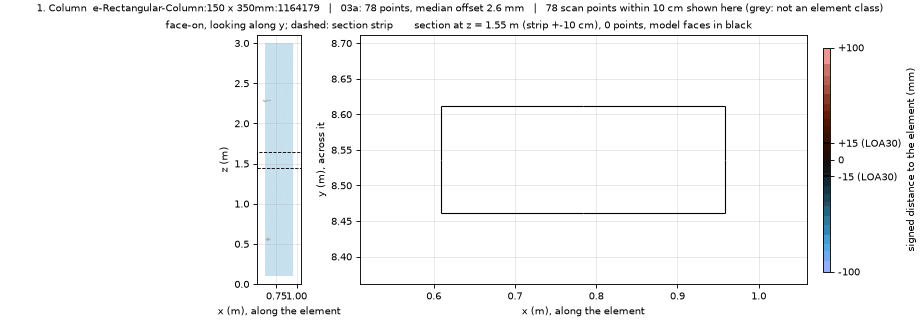

1. IfcColumn  M_Concrete-Rectangular-Column:150 x 350mm:1164179  GlobalId 054HMVvnL1EOSZl$bniLeG
   verdict not confirmed (with oracle labels: not confirmed); 78 points (03a), median signed offset 2.6 mm; reason: too few points   [15 kB]



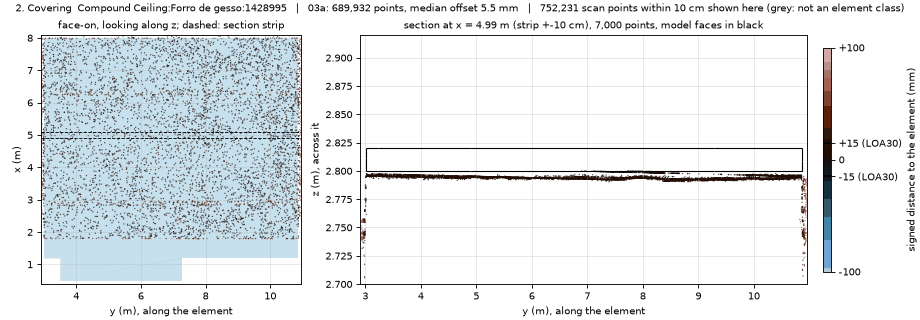

2. IfcCovering  Compound Ceiling:Forro de gesso:1428995  GlobalId 2unE$VYSL2OPIL$6LYYccT
   verdict not confirmed (with oracle labels: not confirmed); 689,932 points (03a), median signed offset 5.5 mm; reason: inconsistent offsets   [49 kB]



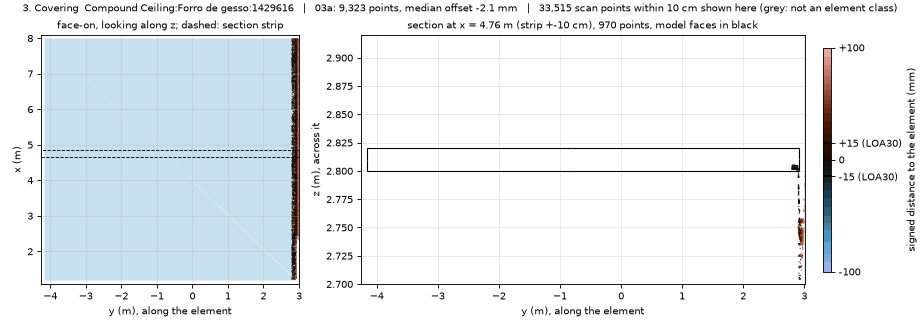

3. IfcCovering  Compound Ceiling:Forro de gesso:1429616  GlobalId 2unE$VYSL2OPIL$6LYYdVk
   verdict not confirmed (with oracle labels: not confirmed); 9,323 points (03a), median signed offset -2.1 mm; reason: mostly outside the room box   [19 kB]



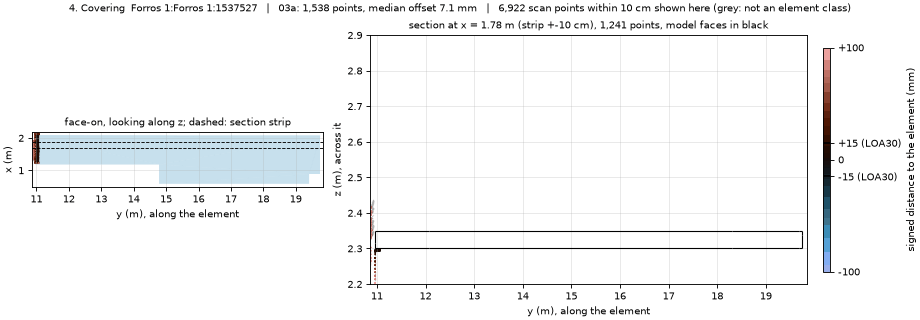

4. IfcCovering  Forros 1:Forros 1:1537527  GlobalId 33gtcvddH7cec8$WOT4fKs
   verdict not confirmed (with oracle labels: not confirmed); 1,538 points (03a), median signed offset 7.1 mm; reason: mostly outside the room box   [15 kB]



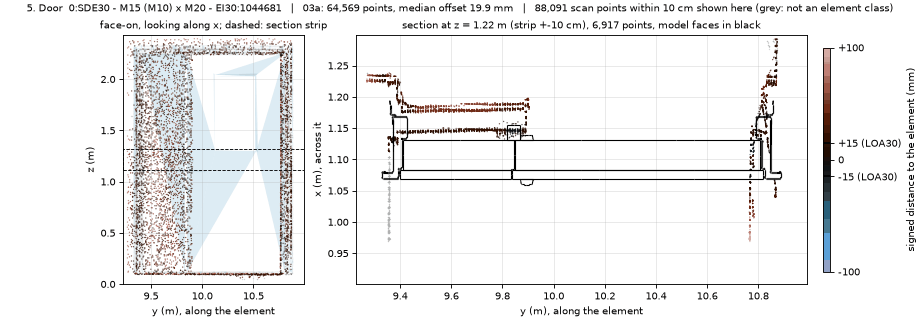

5. IfcDoor  Doors_Door-sets_Swedoor_JELD-WEN_Exterior_Steel_4210_GS1T_Unequal_Double_40:SDE30 - M15 (M10) x M20 - EI30:1044681  GlobalId 0WU0DUvgT6tu4IXFc9kNX5
   verdict not confirmed (with oracle labels: not confirmed); 64,569 points (03a), median signed offset 19.9 mm; reason: inconsistent offsets   [41 kB]



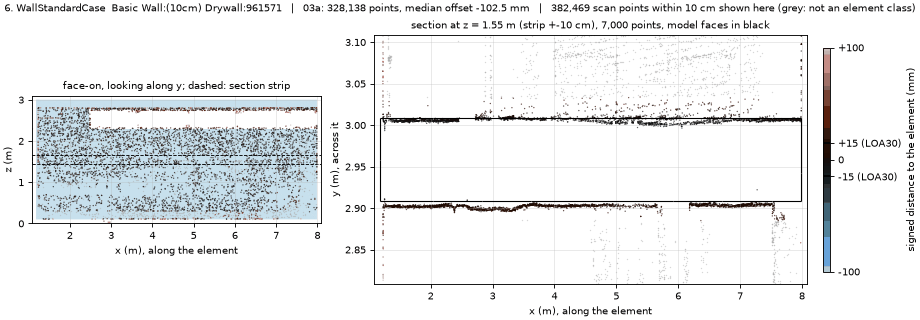

6. IfcWallStandardCase  Basic Wall:(10cm) Drywall:961571  GlobalId 1gsZ4XbYD0qRhfvwOUEI1z
   verdict not confirmed (with oracle labels: not confirmed); 328,138 points (03a), median signed offset -102.5 mm; reason: inconsistent offsets   [47 kB]



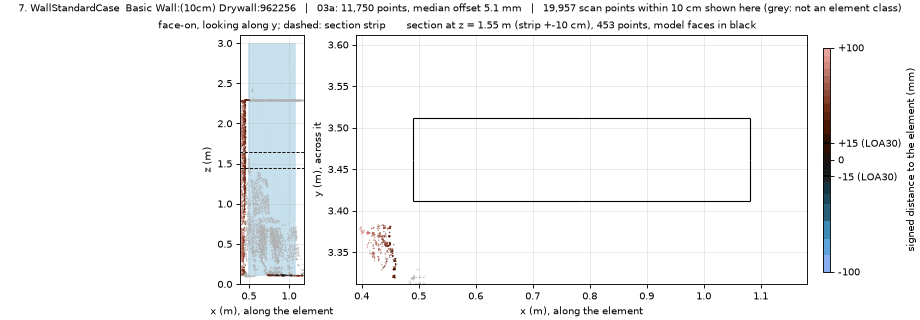

7. IfcWallStandardCase  Basic Wall:(10cm) Drywall:962256  GlobalId 1gsZ4XbYD0qRhfvwOUEIAE
   verdict not confirmed (with oracle labels: not confirmed); 11,750 points (03a), median signed offset 5.1 mm; reason: inconsistent offsets   [21 kB]



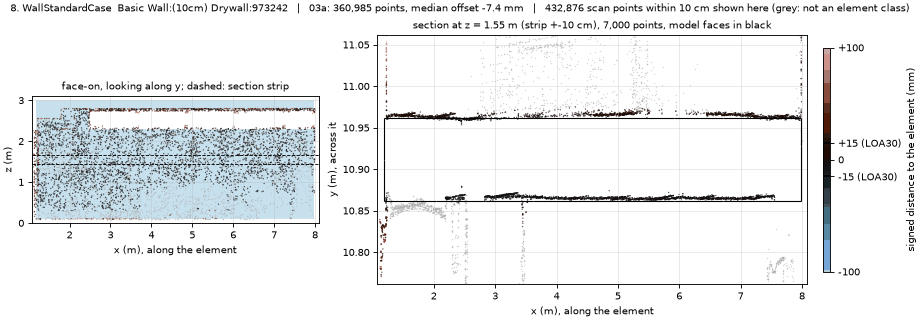

8. IfcWallStandardCase  Basic Wall:(10cm) Drywall:973242  GlobalId 3qeiF73TD1uOeHIcNGcTy8
   verdict not confirmed (with oracle labels: not confirmed); 360,985 points (03a), median signed offset -7.4 mm; reason: inconsistent offsets   [45 kB]



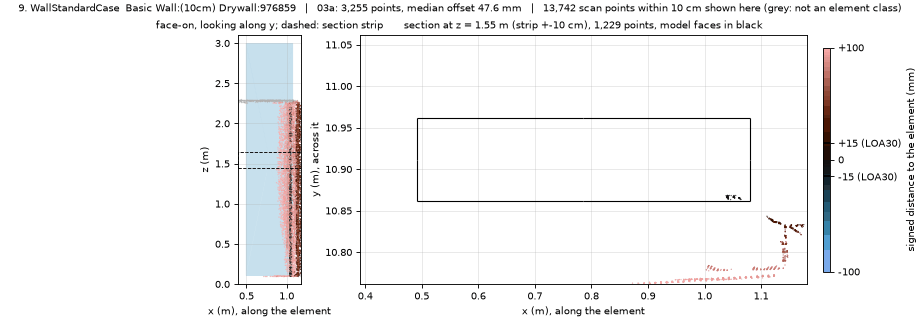

9. IfcWallStandardCase  Basic Wall:(10cm) Drywall:976859  GlobalId 3qeiF73TD1uOeHIcNGcU5f
   verdict not confirmed (with oracle labels: not confirmed); 3,255 points (03a), median signed offset 47.6 mm; reason: inconsistent offsets   [21 kB]



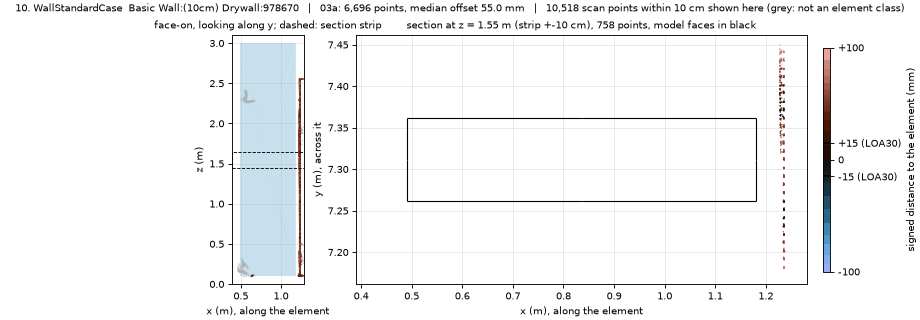

10. IfcWallStandardCase  Basic Wall:(10cm) Drywall:978670  GlobalId 3qeiF73TD1uOeHIcNGcUXS
   verdict not confirmed (with oracle labels: not confirmed); 6,696 points (03a), median signed offset 55.0 mm; reason: inconsistent offsets   [18 kB]



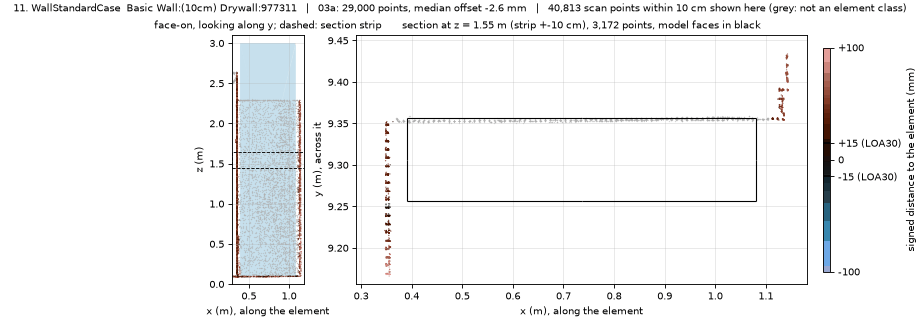

11. IfcWallStandardCase  Basic Wall:(10cm) Drywall:977311  GlobalId 3qeiF73TD1uOeHIcNGcUyj
   verdict not confirmed (with oracle labels: not confirmed); 29,000 points (03a), median signed offset -2.6 mm; reason: inconsistent offsets   [27 kB]



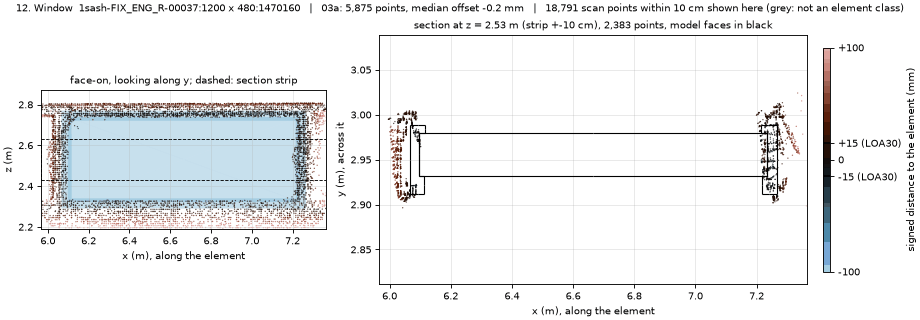

12. IfcWindow  Aluprof_MB-86-ST_E_Alu_Window-1sash-FIX_ENG_R-00037:1200 x 480:1470160  GlobalId 1L1ux2$dP8WO2wsydYGc16
   verdict OK (with oracle labels: OK); 5,875 points (03a), median signed offset -0.2 mm; reason: none   [35 kB]



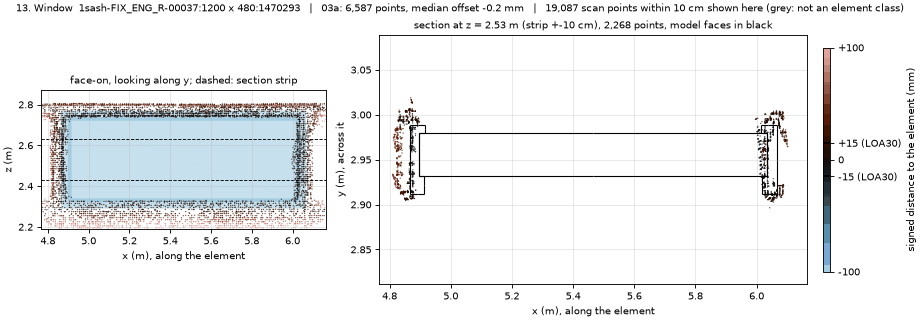

13. IfcWindow  Aluprof_MB-86-ST_E_Alu_Window-1sash-FIX_ENG_R-00037:1200 x 480:1470293  GlobalId 1L1ux2$dP8WO2wsydYGc73
   verdict OK (with oracle labels: OK); 6,587 points (03a), median signed offset -0.2 mm; reason: none   [34 kB]



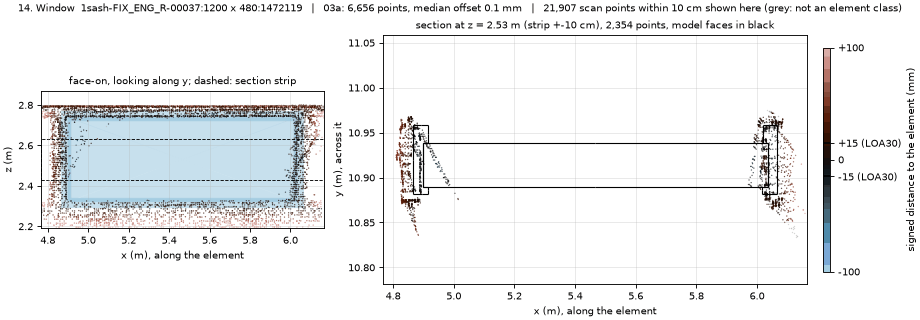

14. IfcWindow  Aluprof_MB-86-ST_E_Alu_Window-1sash-FIX_ENG_R-00037:1200 x 480:1472119  GlobalId 1L1ux2$dP8WO2wsydYGdZX
   verdict OK (with oracle labels: OK); 6,656 points (03a), median signed offset 0.1 mm; reason: none   [35 kB]



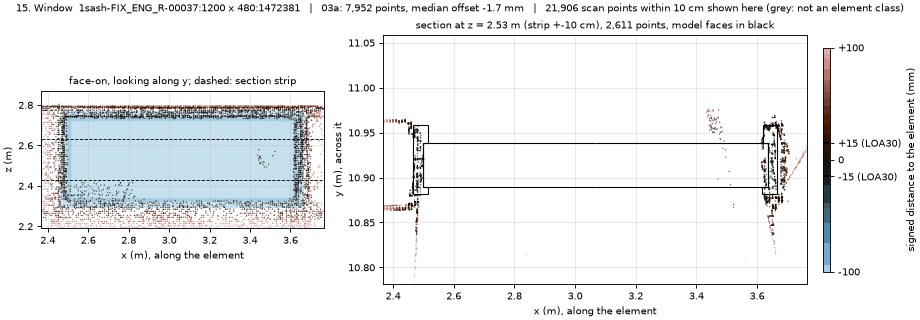

15. IfcWindow  Aluprof_MB-86-ST_E_Alu_Window-1sash-FIX_ENG_R-00037:1200 x 480:1472381  GlobalId 1L1ux2$dP8WO2wsydYGddh
   verdict not confirmed (with oracle labels: not confirmed); 7,952 points (03a), median signed offset -1.7 mm; reason: inconsistent offsets   [35 kB]



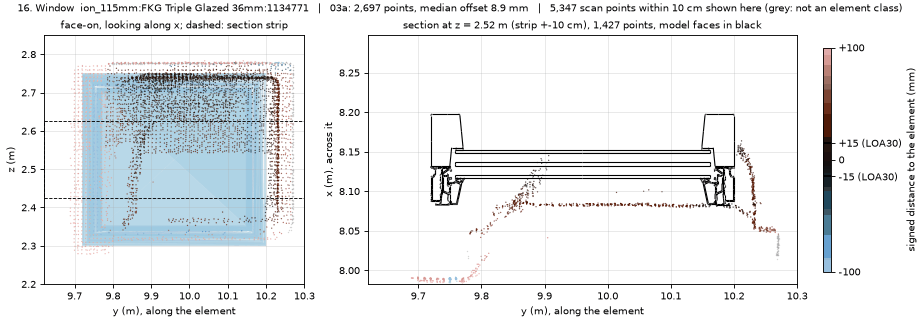

16. IfcWindow  Window-Westcoas_Windows-FKG-Fixed-Frame_Option_115mm:FKG Triple Glazed 36mm:1134771  GlobalId 1clZEeY_LECBal6NIv_ikZ
   verdict not confirmed (with oracle labels: not confirmed); 2,697 points (03a), median signed offset 8.9 mm; reason: inconsistent offsets   [45 kB]



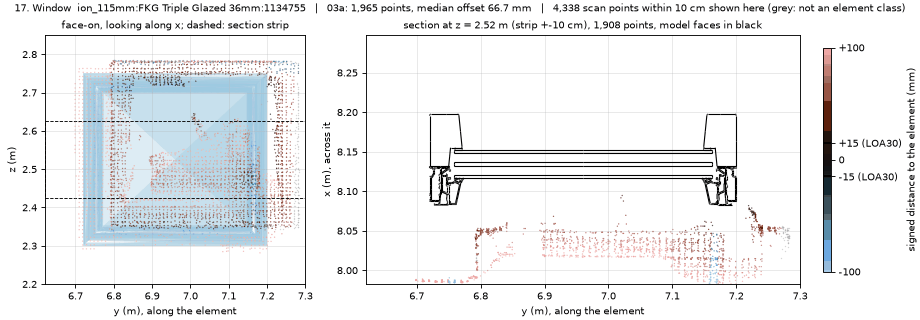

17. IfcWindow  Window-Westcoas_Windows-FKG-Fixed-Frame_Option_115mm:FKG Triple Glazed 36mm:1134755  GlobalId 1clZEeY_LECBal6NIv_ikp
   verdict not confirmed (with oracle labels: not confirmed); 1,965 points (03a), median signed offset 66.7 mm; reason: too few points   [47 kB]



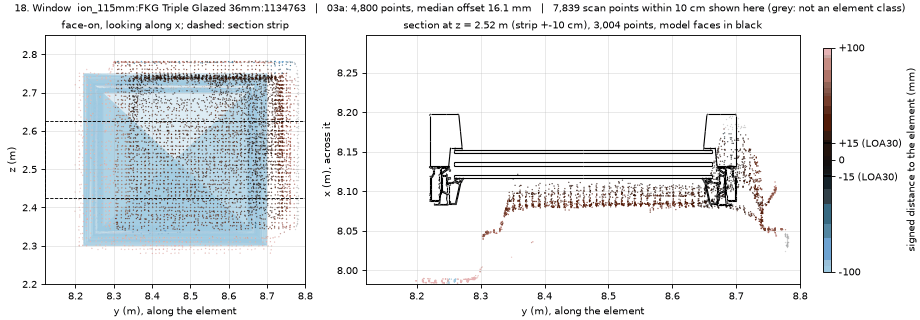

18. IfcWindow  Window-Westcoas_Windows-FKG-Fixed-Frame_Option_115mm:FKG Triple Glazed 36mm:1134763  GlobalId 1clZEeY_LECBal6NIv_ikx
   verdict not confirmed (with oracle labels: not confirmed); 4,800 points (03a), median signed offset 16.1 mm; reason: inconsistent offsets   [52 kB]



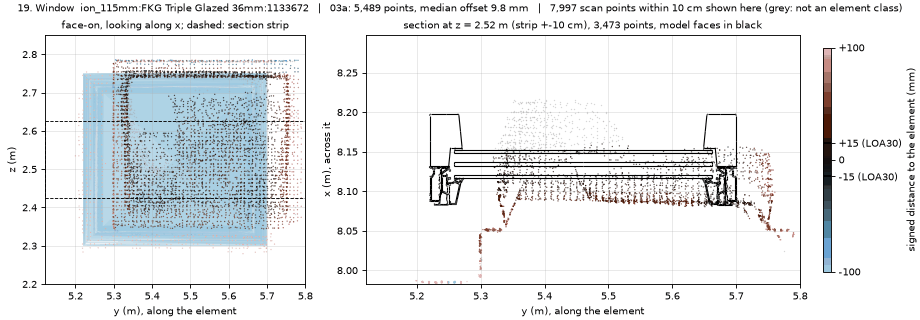

19. IfcWindow  Window-Westcoas_Windows-FKG-Fixed-Frame_Option_115mm:FKG Triple Glazed 36mm:1133672  GlobalId 1clZEeY_LECBal6NIv_jTu
   verdict not confirmed (with oracle labels: not confirmed); 5,489 points (03a), median signed offset 9.8 mm; reason: inconsistent offsets   [53 kB]



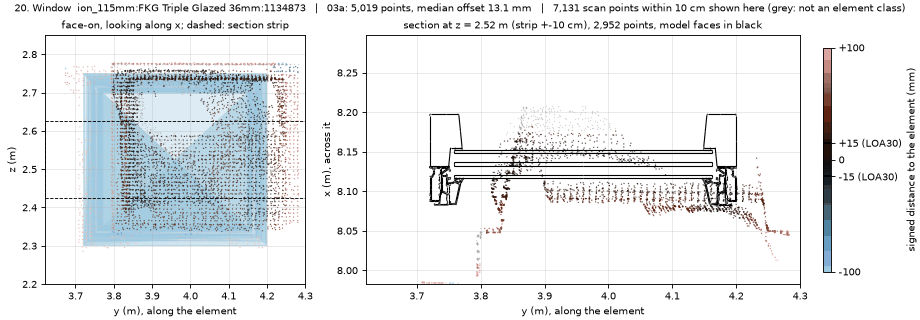

20. IfcWindow  Window-Westcoas_Windows-FKG-Fixed-Frame_Option_115mm:FKG Triple Glazed 36mm:1134873  GlobalId 3iJGmd4gX4uwx4ku7SqaZ_
   verdict not confirmed (with oracle labels: not confirmed); 5,019 points (03a), median signed offset 13.1 mm; reason: inconsistent offsets   [51 kB]

20 close-ups, 35 kB on average (largest 53 kB); peak RSS 0.90 GB


In [5]:
ELEMENT_CLASS_IDS = [CLASS_NAMES.index(n) for n in ELEMENT_SCAN_CLASSES]
AXIS = "xyz"


def view_axes(vertices):
    # ax_t: the element's thinnest bounding-box axis (across it). Along it: for a vertical element (ax_t horizontal) ax_l is the other horizontal
    # axis and ax_w is z, so height is vertical in the face-on view; for a flat one (ax_t is z) ax_l is the longer of x, y and ax_w the other.
    ext = np.ptp(vertices, axis=0)
    ax_t = int(np.argmin(ext))
    rest = [i for i in range(3) if i != ax_t]
    if ax_t != 2:
        return [i for i in rest if i != 2][0], 2, ax_t
    ax_l = max(rest, key=lambda i: ext[i])
    return ax_l, [i for i in rest if i != ax_l][0], ax_t


def section(vertices, faces, axis, value):
    # Line segments where the plane axis == value cuts the triangles: (n, 2, 2), end points in the other two axes (in index order).
    tri = vertices[faces]
    s = tri[:, :, axis] - value
    keep_axes = [i for i in range(3) if i != axis]
    S = np.full((len(tri), 2, 2), np.nan)
    count = np.zeros(len(tri), int)
    for i, j in ((0, 1), (1, 2), (2, 0)):
        idx = np.where(s[:, i] * s[:, j] < 0)[0]
        f = s[idx, i] / (s[idx, i] - s[idx, j])
        S[idx, count[idx]] = tri[idx, i][:, keep_axes] + f[:, None] * (tri[idx, j][:, keep_axes] - tri[idx, i][:, keep_axes])
        count[idx] += 1
    return S[count == 2]


def closeup_data(row):
    # What one close-up shows, chosen but not drawn: the element, its nearby scan points, and the section strip.
    el = elements[row["global_id"]]
    pts, scan_class, signed_d = NEARBY[row["global_id"]]
    ax_l, ax_w, ax_t = view_axes(el.vertices)   # along the element, its other in-surface axis (height for a vertical element), across it
    lo, hi = el.vertices.min(0), el.vertices.max(0)
    centre = (lo + hi) / 2
    mid_l, mid_w = (float(np.median(pts[:, ax_l])), float(np.median(pts[:, ax_w]))) if len(pts) else (centre[ax_l], centre[ax_w])
    if ax_t != 2:
        mid_w = centre[ax_w]   # a vertical element: the section at its mid-height (the median of nearby points can lie in the wall above a window)
    mid_l, mid_w = np.clip(mid_l, lo[ax_l], hi[ax_l]), np.clip(mid_w, lo[ax_w], hi[ax_w])   # a section through the element, not through clutter next to it
    rng = np.random.default_rng(SEED)
    in_strip = np.flatnonzero(np.abs(pts[:, ax_w] - mid_w) <= STRIP)   # the whole element length: no window along it
    return dict(el=el, pts=pts, signed_d=signed_d, is_el=np.isin(scan_class, ELEMENT_CLASS_IDS), ax_l=ax_l, ax_w=ax_w, ax_t=ax_t, lo=lo, hi=hi,
                mid_l=mid_l, mid_w=mid_w, rng=rng, faceon=rng.choice(len(pts), min(len(pts), MAX_FACEON_POINTS), replace=False) if len(pts) else np.zeros(0, int),
                section=rng.choice(in_strip, min(len(in_strip), MAX_SECTION_POINTS), replace=False) if len(in_strip) else in_strip)


def scatter_signed(ax, x, y, d, is_el):
    # Element-class points coloured by signed distance (fixed +-BAND scale), other points grey, drawn first.
    ax.scatter(x[~is_el], y[~is_el], s=1.5, c="#b0b0b0", alpha=0.5, linewidths=0, rasterized=True)
    ax.scatter(x[is_el], y[is_el], s=1.5, c=d[is_el] * 1000, cmap=CMAP, norm=Normalize(-BAND * 1000, BAND * 1000), alpha=0.7, linewidths=0, rasterized=True)


def closeup(row, path):
    cd = closeup_data(row)
    el, pts, ax_l, ax_w, ax_t, lo, hi = cd["el"], cd["pts"], cd["ax_l"], cd["ax_w"], cd["ax_t"], cd["lo"], cd["hi"]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.0), gridspec_kw=dict(width_ratios=[1, 1.5]), layout="constrained")
    # left: face-on (axes l, w)
    tri = el.vertices[el.faces][:, :, [ax_l, ax_w]]
    if len(tri) > MAX_FACEON_TRIANGLES:
        tri = tri[cd["rng"].choice(len(tri), MAX_FACEON_TRIANGLES, replace=False)]
    ax1.add_collection(PolyCollection(tri, facecolor="#9ecae1", edgecolor="none", alpha=0.35, rasterized=True))
    k = cd["faceon"]
    scatter_signed(ax1, pts[k, ax_l], pts[k, ax_w], cd["signed_d"][k], cd["is_el"][k])
    ax1.add_patch(plt.Rectangle((lo[ax_l] - BAND, cd["mid_w"] - STRIP), hi[ax_l] - lo[ax_l] + 2 * BAND, 2 * STRIP, fill=False, ec="k", lw=0.8, ls="--"))
    ax1.set_xlim(lo[ax_l] - BAND, hi[ax_l] + BAND); ax1.set_ylim(lo[ax_w] - BAND, hi[ax_w] + BAND)
    ax1.set_aspect("equal"); ax1.grid(alpha=0.3)
    ax1.set_xlabel(f"{AXIS[ax_l]} (m), along the element"); ax1.set_ylabel(f"{AXIS[ax_w]} (m)")
    ax1.set_title(f"face-on, looking along {AXIS[ax_t]}; dashed: section strip", fontsize=9)
    # right: section (axes l, t) through the strip |w - mid_w| <= STRIP, over the whole element length
    idx = cd["section"]
    scatter_signed(ax2, pts[idx, ax_l], pts[idx, ax_t], cd["signed_d"][idx], cd["is_el"][idx])
    keep_axes = [a for a in range(3) if a != ax_w]
    seg = section(el.vertices, el.faces, ax_w, cd["mid_w"])[:, :, [keep_axes.index(ax_l), keep_axes.index(ax_t)]]
    ax2.add_collection(LineCollection(seg, colors="k", linewidths=1.0))
    ax2.set_xlim(lo[ax_l] - BAND, hi[ax_l] + BAND); ax2.set_ylim(lo[ax_t] - BAND, hi[ax_t] + BAND)
    ax2.set_aspect("auto"); ax2.grid(alpha=0.3)   # not to scale: the across axis is stretched so that millimetres show
    ax2.set_xlabel(f"{AXIS[ax_l]} (m), along the element"); ax2.set_ylabel(f"{AXIS[ax_t]} (m), across it")
    ax2.set_title(f"section at {AXIS[ax_w]} = {cd['mid_w']:.2f} m (strip +-{STRIP * 100:.0f} cm), {len(idx):,} points, model faces in black", fontsize=9)
    cbar = fig.colorbar(ScalarMappable(Normalize(-BAND * 1000, BAND * 1000), CMAP), ax=[ax1, ax2], shrink=0.9, pad=0.02, aspect=30)
    cbar.set_label("signed distance to the element (mm)", fontsize=9)
    cbar.set_ticks([-BAND * 1000, -TOL_MM, 0, TOL_MM, BAND * 1000])
    cbar.set_ticklabels([f"-{BAND * 1000:.0f}", f"-{TOL_MM:.0f} (LOA30)", "0", f"+{TOL_MM:.0f} (LOA30)", f"+{BAND * 1000:.0f}"])
    cbar.ax.tick_params(labelsize=9)
    for tol in (-TOL_MM, TOL_MM):
        cbar.ax.axhline(tol, color="k", lw=1.5)   # the tolerance band: between the two lines is within 15 mm of the element
    med = f"{float(row['median_signed_offset_mm']):.1f} mm" if row["median_signed_offset_mm"] else "none"
    fig.suptitle(f"{row['n']}. {short(row)}  {row['name'][-40:]}   |   03a: {int(row['point_count']):,} points, median offset {med}   |   "
                 f"{len(pts):,} scan points within {BAND * 100:.0f} cm shown here (grey: not an element class)", fontsize=9)
    buf = io.BytesIO()
    fig.savefig(buf, dpi=80, format="png")
    plt.close(fig)
    Image_.open(buf).convert("RGB").quantize(colors=256, method=Image_.Quantize.MEDIANCUT).save(path, optimize=True)   # 256-colour palette: about half the size


for row in drawn:
    path = CLOSEUPS / f"{row['n']:02d}_{short(row)}_{row['global_id']}.png"
    closeup(row, path)
    display(Image(filename=str(path)))
    med = f"{float(row['median_signed_offset_mm']):.1f} mm" if row["median_signed_offset_mm"] else "none (no points)"
    print(f"{row['n']}. {row['ifc_class']}  {row['name']}  GlobalId {row['global_id']}\n"
          f"   verdict {row['verdict']} (with oracle labels: {row['oracle']}); {int(row['point_count']):,} points (03a), median signed offset {med}; "
          f"reason: {row['reason'] or 'none'}   [{path.stat().st_size / 1000:.0f} kB]\n")
sizes = [p.stat().st_size for p in CLOSEUPS.glob("*.png")]
assert len(list(CLOSEUPS.glob("*.png"))) >= N_DRAW and max(sizes) < 100_000, "close-up PNGs missing or above 100 kB"
print(f"{N_DRAW} close-ups, {np.mean(sizes) / 1000:.0f} kB on average (largest {max(sizes) / 1000:.0f} kB); peak RSS {peak_rss_gb():.2f} GB")

## 4. Hand check

The judgements are in `notebooks/05b_hand_check.csv`, filled in by the author from the close-ups above. `judgement` is what the element's verdict should be (`OK`, `shifted`, `not confirmed`); `note` is free text. Agreement is `judgement == verdict` over the filled rows. The criterion is at least 80 % agreement with all 20 filled; until then the result is PENDING.

In [6]:
drawn_by_id = {r["global_id"]: r for r in drawn}
for h in hand:  # score against 03a's current verdict
    h["verdict"] = drawn_by_id[h["global_id"]]["verdict"]
HAND = hand_check_result(hand, n_required=GATE_N_ELEMENTS, min_share=GATE_MIN_AGREE)
print(f"{'n':>2s}  {'class':18s} {'verdict':14s} {'judgement':14s} {'agree':>5s}  note")
for h in hand:
    print(f"{h['n']:>2s}  {h['ifc_class'][3:]:18s} {h['verdict']:14s} {h['judgement'] or '-':14s} {('yes' if h['judgement'] == h['verdict'] else 'NO') if h['judgement'] else '':>5s}  {h['note']}")
share = "n/a" if HAND["share"] is None else f"{HAND['share']:.0%}"
print(f"\nfilled {HAND['n_filled']} of {len(hand)}; agree {HAND['n_agree']} of {HAND['n_filled']} ({share}); needed: all {GATE_N_ELEMENTS} filled and >= {GATE_MIN_AGREE:.0%}")
print(f"hand check: {HAND['status']}")

 n  class              verdict        judgement      agree  note
 1  Column             not confirmed  not confirmed    yes  
 2  Covering           not confirmed  OK                NO  
 3  Covering           not confirmed  not confirmed    yes  
 4  Covering           not confirmed  not confirmed    yes  
 5  Door               not confirmed  shifted           NO  wide leaf no points (likely open); narrow leaf two parallel surfaces ~2 cm and ~6 cm off the model face
 6  WallStandardCase   not confirmed  OK                NO  
 7  WallStandardCase   not confirmed  not confirmed    yes  
 8  WallStandardCase   not confirmed  OK                NO  
 9  WallStandardCase   not confirmed  not confirmed    yes  
10  WallStandardCase   not confirmed  not confirmed    yes  
11  WallStandardCase   not confirmed  not confirmed    yes  
12  Window             OK             OK               yes  
13  Window             OK             OK               yes  
14  Window             OK             O

## 5. Perturbed-model criterion (from 03b)

Read from 03b's score tables, one row per room element. **False-flag reading:** the roadmap says "falsely flagged shifted or missing". *Missing* is unreachable here (01 recovered no scanner positions, and `CONTEXT.md` merges missing and not visible into *not confirmed*), so the false-flag count is the untouched elements that come out *shifted*, as in 03b and the #11 comment. How many untouched elements are *not confirmed* is printed as context: if *not confirmed* were read as *missing*, the clause would fail. Known answers first: every row's `expected` follows from the rule (a move within the 15 mm tolerance expects OK, a larger move expects shifted, an element not built expects not confirmed), the injected offsets equal the manifest's, and the untouched rows are the elements the manifest does not list.

In [7]:
changes = {c["global_id"]: c for c in manifest["changes"]}
EXPECTED_WHEN_NOT_BUILT = "not confirmed"
for v, rows in scores.items():
    assert {r["global_id"] for r in rows if r["change"]} == set(changes), f"{v}: the changed rows are not the manifest's changes"
    for r in rows:
        c = changes.get(r["global_id"])
        if not c:
            assert r["expected"] == "" and r["change"] == ""
            continue
        assert r["change"] == c["change"]
        if c["change"] == "moved":
            mm = float(np.linalg.norm(c["offset_m"])) * 1000
            assert abs(float(r["injected_offset_mm"]) - mm) < 0.5
            assert r["expected"] == ("OK" if mm <= TOL_MM else "shifted")
        else:
            assert r["expected"] == EXPECTED_WHEN_NOT_BUILT

PERT = {v: perturbed_result(rows, TOL_MM, GATE_MAX_FALSE_SHARE) for v, rows in scores.items()}
for v, rows in scores.items():
    pert = PERT[v]
    beyond_ids = {id(r) for r in pert["beyond_rows"]}   # the rows perturbed_result counted as beyond tolerance
    print(f"=== {v} ===" + ("   <- the criterion's run (no oracle labels)" if v == "no_labels" else "   (context)"))
    print(f"{'change':10s} {'element':30s} {'injected':>9s} {'beyond tol.':>12s} {'expected':>14s} {'actual':>14s}  right")
    for r in rows:
        if r["change"]:
            inj = f"{float(r['injected_offset_mm']):.0f} mm" if r["injected_offset_mm"] != "" else "-"
            print(f"{r['change']:10s} {(short(r) + ' ' + r['name'][-14:]):30s} {inj:>9s} {'yes' if id(r) in beyond_ids else 'no (control)':>12s} {r['expected']:>14s} {r['actual']:>14s}  {'yes' if r['actual'] == r['expected'] else 'NO'}")
    for r in pert["false_rows"]:
        print(f"  untouched, flagged {r['actual']}: {short(r)} {r['name'][-24:]} (baseline {r['baseline']}, median {float(r['median_signed_offset_mm']):.1f} mm)")
    print(f"(i)  changes beyond tolerance with the right verdict: {pert['n_beyond_right']} of {pert['n_beyond']}  -> {'ok' if pert['changes_ok'] else 'FAIL'}"
          f"   (control, within tolerance: {pert['n_control_right']} of {pert['n_control']} right; counting it, {pert['n_beyond_right'] + pert['n_control_right']} of {pert['n_beyond'] + pert['n_control']}, the figure 03b prints)")
    print(f"(ii) untouched elements flagged shifted (missing is unreachable here, see 3): {pert['n_false']} of {pert['n_untouched']} = {pert['share_false']:.1%}  (at most {GATE_MAX_FALSE_SHARE:.0%})  -> {'ok' if pert['false_ok'] else 'FAIL'}")
    base_nc = sum(r["baseline"] == "not confirmed" for r in rows if not r["change"])
    print(f"     context: untouched elements that are not confirmed: {pert['n_untouched_not_confirmed']} of {pert['n_untouched']} ({base_nc} of them on the real model, before any change). "
          f"Not confirmed is not a false flag; if it were read as missing, {pert['n_false'] + pert['n_untouched_not_confirmed']} of {pert['n_untouched']} would be flagged and clause (ii) would fail.")
    print(f"perturbed-model criterion, {v}: {pert['status']}\n")

=== no_labels ===   <- the criterion's run (no oracle labels)
change     element                         injected  beyond tol.       expected         actual  right
not_built  Column  350mm:1164179                  -          yes  not confirmed  not confirmed  yes
not_built  Door - EI30:1044681                    -          yes  not confirmed  not confirmed  yes
moved      WallStandardCase Drywall:961571     10 mm no (control)             OK  not confirmed  NO
moved      WallStandardCase Drywall:973242     30 mm          yes        shifted  not confirmed  NO
moved      WallStandardCase Drywall:978670    100 mm          yes        shifted  not confirmed  NO
not_built  WallStandardCase Drywall:979093         -          yes  not confirmed  not confirmed  yes
  untouched, flagged shifted: WallStandardCase ll:(10cm) Drywall:976859 (baseline not confirmed, median 92.9 mm)
(i)  changes beyond tolerance with the right verdict: 3 of 5  -> FAIL   (control, within tolerance: 0 of 1 right; counting

## 6. Registration criterion (from 05a)

05a's `registration.csv`, one row per PC2Model sample: `success` is 05a's flag (best of five RANSAC seeds picked by ICP fitness; rotation error <= 2 degrees, centroid error <= 5 cm, scale error <= 1 % on scaled samples). The cell re-derives each flag from the three errors as a check, then counts.

In [8]:
print(f"{'sample':58s} {'scaled':>6s} {'rot deg':>8s} {'centroid m':>11s} {'scale err %':>12s} {'success':>8s}")
for r in registration:
    scaled = r["scaled"] == "True"
    derived = float(r["rot_deg"]) <= GATE_REG_ROT_DEG and float(r["centroid_m"]) <= GATE_REG_TRANS_M and (not scaled or float(r["scale_err_pct"]) <= GATE_REG_SCALE_PCT)
    assert derived == (r["success"] == "True"), f"{r['sample']}: success flag differs from the thresholds"
    print(f"{Path(r['sample']).name[:58]:58s} {'yes' if scaled else 'no':>6s} {float(r['rot_deg']):8.2f} {float(r['centroid_m']):11.3f} {float(r['scale_err_pct']):12.2f} {r['success']:>8s}")
REG = registration_result(registration, GATE_REG_MIN_SUCCESS)
by_cat = {c: sum(r["success"] == "True" for r in registration if r["category"] == c) for c in dict.fromkeys(r["category"] for r in registration)}
print(f"\nsuccessful: {REG['n_success']} of {REG['n_total']} (needed {GATE_REG_MIN_SUCCESS}); by category: " + ", ".join(f"{c} {n}/3" for c, n in by_cat.items()))
print(f"registration criterion: {REG['status']}")

sample                                                     scaled  rot deg  centroid m  scale err %  success
house_23-sketchfab                                            yes     0.23       0.070         3.90    False
house_13-sketchfab                                             no     0.02       0.002         0.00     True
house_18-sketchfab                                             no     0.54       0.041         0.00     True
indoor_modelling_4-ISPRS_indoor_modelling-UoM                 yes     0.05       0.024         1.55    False
indoor_modelling_3-ISPRS_indoor_modelling-UVigo                no     0.09       0.023         0.00     True
indoor_modelling_0-ISPRS_indoor_modelling-TUBS1               yes     0.13       0.171         5.29    False
real-indoor_modelling_1-ISPRS_indoor_modelling-TUBS2          yes     0.18       0.221         7.40    False
real-indoor_modelling_3-ISPRS_indoor_modelling-UVigo           no     0.33       0.139         0.00    False
real-indoor_modelli

## 7. The gate

Pass or fail per criterion, and overall. The perturbed-model line is the no-labels run (the realistic one); the oracle-labels run is in section 5 for context.

In [9]:
pert_nl = PERT["no_labels"]
parts = {"registration (05a)": REG["status"], "perturbed model (03b, no labels)": pert_nl["status"], "hand check (05b)": HAND["status"]}
OVERALL = combine(list(parts.values()))
print(f"registration: {REG['n_success']} of {REG['n_total']} samples succeed (needed {GATE_REG_MIN_SUCCESS})  -> {REG['status']}")
print(f"perturbed model: {pert_nl['n_beyond_right']} of {pert_nl['n_beyond']} changes beyond tolerance right; {pert_nl['n_false']} of {pert_nl['n_untouched']} untouched falsely flagged shifted "
      f"({pert_nl['share_false']:.1%}, at most {GATE_MAX_FALSE_SHARE:.0%})  -> {pert_nl['status']}")
print(f"hand check: {HAND['n_agree']} of {HAND['n_filled']} filled agree" + ("" if HAND["share"] is None else f" ({HAND['share']:.0%})") +
      f"; needed all {GATE_N_ELEMENTS} filled and >= {GATE_MIN_AGREE:.0%}  -> {HAND['status']}")
decided = [k for k, v in parts.items() if v == "FAIL"]
pending = [k for k, v in parts.items() if v == "PENDING"]
print(f"\nOVERALL: {OVERALL}" + (f"  (decided by: {', '.join(decided)}" + (f"; still pending, and it cannot change this: {', '.join(pending)})" if pending else ")") if decided else
                                 (f"  (waiting for: {', '.join(pending)})" if pending else "  (all three criteria pass: worth formalising)")))
if OVERALL == "FAIL":
    print("\nThe roadmap allows at most one week of tuning inside Phase 0.5. If the gate still fails after that, the result is written up as a negative "
          "result and the project continues; it motivates the learned registration under Later. Tuning that changes 03a's verdicts changes the draw and invalidates "
          "the drawn 20 and the judgement CSV (section 2 raises if the draw differs).")
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "gate.json").write_text(json.dumps({"overall": OVERALL, "registration": REG, "perturbed_no_labels": pert_nl, "perturbed_oracle_labels": PERT["oracle_labels"],
                                           "hand_check": HAND, "seed": SEED, "drawn": [r["global_id"] for r in drawn]}, indent=1))

registration: 4 of 9 samples succeed (needed 6)  -> FAIL
perturbed model: 3 of 5 changes beyond tolerance right; 1 of 29 untouched falsely flagged shifted (3.4%, at most 10%)  -> FAIL
hand check: 15 of 20 filled agree (75%); needed all 20 filled and >= 80%  -> FAIL

OVERALL: FAIL  (decided by: registration (05a), perturbed model (03b, no labels), hand check (05b))

The roadmap allows at most one week of tuning inside Phase 0.5. If the gate still fails after that, the result is written up as a negative result and the project continues; it motivates the learned registration under Later. Tuning that changes 03a's verdicts changes the draw and invalidates the drawn 20 and the judgement CSV (section 2 raises if the draw differs).


8316

In [10]:
print(f"peak RSS {peak_rss_gb():.2f} GB, notebook run {time.time() - T_NOTEBOOK:.0f} s")

peak RSS 0.90 GB, notebook run 153 s


## Answer

**The gate fails on all three criteria.** Overall: **FAIL**, so by the roadmap the pipeline is not yet worth formalising as it stands. The roadmap then allows at most one week of tuning inside Phase 0.5, and a negative-result write-up if the gate still fails after it.

| criterion | result | status |
|---|---|---|
| Registration (05a), >= 6 of 9 samples succeed | **4 of 9** (house 2 of 3, simulated indoor 1 of 3, real indoor 1 of 3) | **FAIL** |
| Perturbed model (03b, no labels), every change beyond tolerance right | **3 of 5** right (the not-built column, door and wall); both moves beyond tolerance (3 and 10 cm) come out not confirmed, not shifted | **FAIL** |
| Perturbed model, at most 10 % of untouched falsely flagged shifted (or missing) | **1 of 29 = 3.4 %** (`Drywall:976859`, not confirmed on the real model, shifted at +93 mm after the perturbation); shifted-only count, see below | ok |
| Hand check, all 20 filled and >= 80 % agree | **15 of 20 = 75 %** agree | **FAIL** |

**False-flag reading.** The roadmap says "falsely flagged shifted or missing". *Missing* is unreachable here (01 recovered no scanner positions; `CONTEXT.md` merges missing and not visible into *not confirmed*), so the count is shifted-only, as in 03b and the #11 comment. For context, 28 of the 29 untouched elements are *not confirmed* after the perturbation (24 on the real model, before any change); if *not confirmed* were read as *missing*, all 29 of 29 would be flagged and the clause would fail. The shifted-only reading is the one used, but the clause passes only because of it.

**Perturbed model, in detail.** The 1 cm control (it must stay OK, within the 15 mm tolerance) comes out not confirmed in both runs and is not part of the criterion; counting it, the totals are 3 of 6 without labels and 2 of 6 with oracle labels, the figures 03b prints and issue #11 reports. With oracle labels the not-built wall `Drywall:979093` also comes out shifted (it was already shifted on the real model), so 2 of 5 are right, and 2 of 29 untouched elements are falsely flagged (6.9 %): the false-flag clause passes in both runs, the changes clause fails in both. The failure is the real-model baseline's: only 1 of the 35 elements is shifted and 5 are OK without labels, so there is little for a perturbation to turn into the right verdict (issues #17 and #18).

**Registration, in detail.** Best of five RANSAC seeds picked by ICP fitness. All four scaled samples fail the 1 % scale criterion (scale errors 1.5, 3.9, 5.3 and 7.4 %; their centroid errors are 2.4, 7.0, 17 and 22 cm). Of the five unscaled samples four succeed; the failure is the real UVigo scan (rotation 0.33 degrees, but centroid error 13.9 cm). 05a has the table and the discussion.

**The draw (SEED 0).** 20 of the 35 elements: 1 column, 3 coverings, 1 door, 6 walls, 9 windows and no slab. By verdict (no labels): **17 not confirmed, 3 OK, 0 shifted** (population: 29, 5, 1). The oracle-labels verdict is the same for all 20. Two things to keep in mind when reading the agreement. First, 17 of 20 verdicts are not confirmed, which is also the default verdict of the logic (anything that is not clearly OK or one shifted cluster), so agreement on this draw measures mostly whether "not confirmed" is a fair description; the only shifted element of the room (`Drywall:979093`) was not drawn, so the hand check cannot say whether a shifted verdict is right. Second, 20 of 35 is 57 % of the room, so the sample is not independent of it.

**What a close-up shows.** The black lines on the right are the model's faces; points of an element class are coloured by signed distance to the element (dark: on it, within about 15 mm; light red or blue: off it, scale +-10 cm), grey points are clutter or unassigned. For example, element 14 (a window) has dark points at its frame but none in the glass, so a window shows its frame and the wall around it, not a surface; element 6 (a wall) has scan points along both of its faces and clutter points beside them.

**The hand check.** The author judged all 20 close-ups (`notebooks/05b_hand_check.csv`, with notes on elements 5, 16, 18 and 19). 15 of 20 agree with 03a (75 %, below the 80 % threshold). All 5 disagreements go one way: 03a says *not confirmed* where the author saw a definite answer, OK for element 2 (a ceiling), 6 and 8 (walls) and 15 (a window), and shifted for element 5 (a double door whose wide leaf has no points, likely open, and whose narrow leaf shows surfaces about 2 and 6 cm off the model face). No verdict of 03a was judged wrong in the other direction: the 3 OK verdicts were all confirmed, and 12 of the 17 *not confirmed* were too. So on this draw 03a errs towards *not confirmed*, the same failure the perturbed-model criterion shows (moves of 3 and 10 cm come out not confirmed) and the one issues #17 and #18 describe for walls. Three of the FKG windows (16, 18, 19) show a flat surface about 4 cm in front of the glass across the opening, likely a blind; the author judged them *not confirmed*, agreeing with 03a.

**What to do next.** The roadmap's rule for a failed gate applies: at most one week of tuning inside Phase 0.5, then a negative-result write-up if it still fails. If tuning changes 03a's verdicts, the draw changes: the drawn 20 and the judgement CSV are then invalid, and the notebook raises until the CSV is deleted and judged again. The run took 20 to 160 s (depending on machine load) and peaked at about 0.9 to 1.6 GB RSS.
